# Our run against AMW, chip by chip

Does our `detect.py` reproduce AMW's published quarterly detections? For every chip (the
same 48 px square on both sides) we compare the raw detection (confidence > 0.4) and the
score itself. Area is left out.

Set the run in the first cell, then *Run All*. Section 0 shows what both tables look like.
The notebook only reads. Needs AMW's files in `amw_comparison/data/amw/` (see `README.md`).

In [ ]:
RUN = "tests_output/test_region_2026-10-19"        # the quick check: 36 tiles in subregion 2
SUBREGION = 2
# RUN = "tests_output/amw_compare_s3_2026-10-19"   # the long run: all of subregion 3
# SUBREGION = 3
QUARTERS = ["2026Q1", "2026Q2", "2026Q3"]          # quarters not scored in the run are skipped
CHECK_LAST_DAY = False   # True: section 5e asks Earth Engine where the last day's scenes lie

import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "panel_pipeline").is_dir())
sys.path.insert(0, str(REPO / "amw_comparison"))

from datetime import datetime
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import compare

RUN = REPO / RUN
pd.set_option("display.float_format", "{:,.5f}".format)   # AMW's key has 5 decimals

## 0. The two tables

**AMW** publishes one file per quarter, with a row for every chip it scored above 0.4: the
chip's square (`geometry`), its score (`confidence`) and the six model votes (`preds`). There
is no chip ID; the square is the chip. The two key columns are added here: they are how
section 2 finds the same chip on our side. These are the files in `amw_comparison/data/amw/`.

In [ ]:
import geopandas as gpd
import pyogrio
path = compare.amw_file(QUARTERS[-1])
head = gpd.read_file(path, rows=5)
head["amw_key_x"], head["amw_key_y"] = compare.centroid_key(head)   # added here (AMW's function)
print(f"{path.name}: {pyogrio.read_info(path)['features']:,} rows")
head

amazon_basin_Q326_t0.4.geojson: 141,868 rows


,confidence,preds,geometry,amw_key_x,amw_key_y
0,0.55837,[0.08991893 0.35511446 0.98397636 0.8111113 0...,"POLYGON ((-78.51553 -4.03591, -78.51553 -4.040...",-78.51336,-4.03809
1,0.40526,[0.00912227 0.38610217 0.9796135 0.18175401 0...,"POLYGON ((-78.51553 -4.03808, -78.51553 -4.042...",-78.51336,-4.04026
2,0.46602,[7.9042510e-03 8.6182344e-01 3.5066527e-01 1.0...,"POLYGON ((-78.51336 -4.03808, -78.51336 -4.042...",-78.51119,-4.04026
3,0.63623,[0.12539396 0.5894108 0.99455166 0.5179723 0...,"POLYGON ((-78.5112 -4.03591, -78.5112 -4.04026...",-78.50903,-4.03809
4,0.59724,[0.00619723 0.65044177 0.90627384 0.46472853 0...,"POLYGON ((-78.53054 -4.03388, -78.53054 -4.038...",-78.52838,-4.03606


The `_t0.43_t-iso0.75` file is the same table after AMW's filter (every chip needs 0.43, a
chip with fewer than 5 detections within 3 km needs 0.75), with `kth_neighbor_km` added. We
compare against the unfiltered file above.

In [ ]:
path = compare.amw_file(QUARTERS[-1], "postprocessed")
print(f"{path.name}: {pyogrio.read_info(path)['features']:,} rows")
gpd.read_file(path, rows=5)

amazon_basin_Q326_t0.43_t-iso0.75.geojson: 128,051 rows


,confidence,preds,kth_neighbor_km,geometry
0,0.55837,[0.08991893 0.35511446 0.98397636 0.8111113 0...,1.01665,"POLYGON ((-78.51553 -4.03591, -78.51553 -4.040..."
1,0.46602,[7.9042510e-03 8.6182344e-01 3.5066527e-01 1.0...,1.25236,"POLYGON ((-78.51336 -4.03808, -78.51336 -4.042..."
2,0.63623,[0.12539396 0.5894108 0.99455166 0.5179723 0...,1.50410,"POLYGON ((-78.5112 -4.03591, -78.5112 -4.04026..."
3,0.59724,[0.00619723 0.65044177 0.90627384 0.46472853 0...,2.03733,"POLYGON ((-78.53054 -4.03388, -78.53054 -4.038..."
4,0.48139,[0.09276147 0.89308184 0.5029895 0.47647232 0...,1.25236,"POLYGON ((-78.52404 -4.03606, -78.52404 -4.040..."


AMW's closest thing to a panel is `amazon_basin_detections.geojson`: one row per location,
with `onset` (the year mining there began, or the quarter it first appeared for the newest
rows) and `status` (`confirmed` once seen again the following year, else `provisional`).
It has no row per quarter, so the chip-by-chip comparison uses the quarterly files. It is
shown here only if it is in the folder.

In [ ]:
panel = compare.AMW_PANEL
if panel.exists():
    print(f"{panel.name}: {pyogrio.read_info(panel)['features']:,} rows")
    display(gpd.read_file(panel, rows=5))
else:
    print(f"{panel.name} is not in {panel.parent.relative_to(REPO)}/, skipped")

amazon_basin_detections.geojson: 232,751 rows


,confidence,preds,kth_neighbor_km,onset,onset_year,status,confirmed_in,n_witness,geometry
0,0.64023,[0.03144935 0.69934154 0.9998982 0.5003735 0...,2.03948,2018,2018,confirmed,2019,2,"POLYGON ((-78.70892 -4.37708, -78.70892 -4.381..."
1,0.71323,[0.02782322 0.87836003 0.99753684 0.62818396 0...,2.28303,2018,2018,confirmed,2019,2,"POLYGON ((-78.70675 -4.37708, -78.70675 -4.381..."
2,0.77778,[0.45259953 0.89168435 0.9974273 0.71248794 0...,0.55880,2018,2018,confirmed,2019,2,"POLYGON ((-78.73478 -4.37723, -78.73478 -4.381..."
3,0.72886,[0.252006 0.9364146 0.94379634 0.5720056 0...,1.11758,2018,2018,confirmed,2019,2,"POLYGON ((-78.72828 -4.37288, -78.72828 -4.377..."
4,0.56305,[0.26013893 0.8851775 0.34751964 0.6948044 0...,0.76880,2018,2018,confirmed,2019,2,"POLYGON ((-78.64277 -4.04056, -78.64277 -4.044..."


**Ours** is a panel in long form: one row per chip per quarter, for every chip, detected or
not. `period` and `subregion` come from the folder names (`period=2026Q2/subregion=3/`).
`plan/chips.parquet` has one row per chip: where it is, and AMW's key for it.

In [ ]:
import pyarrow.dataset as ds
import pyarrow.parquet as pq
scores = ds.dataset(RUN / "detect" / "quarterly", partitioning="hive", format="parquet")
print(f"detect/quarterly: {scores.count_rows():,} rows (chips × quarters scored)")
display(scores.head(5).to_pandas())
plan = pq.ParquetFile(RUN / "plan" / "chips.parquet")
print(f"plan/chips.parquet: {plan.metadata.num_rows:,} rows")
next(plan.iter_batches(batch_size=5)).to_pandas()

detect/quarterly: 57,132 rows (chips × quarters scored)


,chip_id,confidence,vote_1,vote_2,vote_3,vote_4,vote_5,vote_6,n_obs,n_clear,empty_share,period,subregion
0,205075101000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,20.00000,7.66840,0.00000,2026Q1,2
1,205075101001,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,20.00000,8.17274,0.00000,2026Q1,2
2,205075101002,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,20.00000,8.86458,0.00000,2026Q1,2
3,205075101003,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,20.00000,9.61719,0.00000,2026Q1,2
4,205075101004,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,20.00000,10.00391,0.00000,2026Q1,2


plan/chips.parquet: 19,044 rows


,chip_id,tile_key,chip_index,minx,miny,maxx,maxy,amw_key_x,amw_key_y,in_region,in_andes
0,205075101000,552:12:10.0:20:7:101,0,-62.65250,5.09051,-62.64816,5.09486,-62.65033,5.09268,True,False
1,205075101001,552:12:10.0:20:7:101,1,-62.65250,5.08834,-62.64816,5.09268,-62.65033,5.09051,True,False
2,205075101002,552:12:10.0:20:7:101,2,-62.65250,5.08617,-62.64816,5.09051,-62.65033,5.08834,True,False
3,205075101003,552:12:10.0:20:7:101,3,-62.65250,5.08399,-62.64816,5.08834,-62.65033,5.08617,True,False
4,205075101004,552:12:10.0:20:7:101,4,-62.65250,5.08182,-62.64816,5.08617,-62.65033,5.08399,True,False


## 1. Inputs

Our side must be complete with no failed tiles: a missing tile would look like "AMW
detected it, we didn't". The AMW file's fingerprint (sha256) records which version we compared
against, since AMW replaces its files when it re-runs.

In [ ]:
rows = []
for q in QUARTERS:
    path = compare.amw_file(q)
    try:
        status = compare.read_status(RUN, q, SUBREGION)
    except FileNotFoundError:
        print(f"{q}: not scored in this run, skipped")
        continue
    session = status["sessions"][-1]
    rows.append({"quarter": q, "complete": status["complete"],
                 "tiles": f"{status['tiles_saved']:,}/{status['tiles_planned']:,}",
                 "failed": len(status["tiles_failed"]),
                 "scored (UTC)": session["started_utc"][:16],
                 "image cache": bool(session.get("image_cache")),
                 "AMW file": path.name if path.exists() else "MISSING",
                 "AMW sha256": compare.sha256(path)[:12] if path.exists() else "",
                 "AMW file saved": f"{datetime.fromtimestamp(path.stat().st_mtime):%Y-%m-%d}" if path.exists() else ""})
assert rows, f"none of {QUARTERS} is scored for subregion {SUBREGION} in this run"
inputs = pd.DataFrame(rows).set_index("quarter")
QUARTERS = [q for q in inputs.index if inputs.loc[q, "complete"] and inputs.loc[q, "AMW file"] != "MISSING"]
assert QUARTERS, "nothing to compare: finish the run (rerun detect.py) or add AMW's files"
inputs

,complete,tiles,failed,scored (UTC),image cache,AMW file,AMW sha256,AMW file saved
quarter,,,,,,,,
2026Q1,True,36/36,0,2026-10-19T10:00,True,amazon_basin_Q126_t0.4.geojson,b4f35df7398e,2026-10-19
2026Q2,True,36/36,0,2026-10-19T10:02,True,amazon_basin_Q226_t0.4.geojson,5c57a94daca9,2026-10-19
2026Q3,True,36/36,0,2026-10-19T10:04,True,amazon_basin_Q326_t0.4.geojson,f2f56a0484f2,2026-10-19


## 2. Join

AMW's file covers the whole Amazon, so most of its rows are elsewhere. Every AMW chip that
sits on our chip grid must land on one of our chips. `should have matched` counts those that
didn't and must be 0; otherwise the grids differ and nothing below can be trusted.

To keep memory small, only chips detected by either side are kept after this step.

In [ ]:
chips = compare.read_chips(RUN, SUBREGION)
joins, counts, gaps, quality, kept = {}, {}, {}, {}, {}
for q in QUARTERS:
    ours = compare.read_ours(RUN, q, SUBREGION)
    amw = compare.read_amw(compare.amw_file(q))
    assert len(ours) == len(chips) and ours["chip_id"].is_unique, "our scores and the plan disagree"
    table, unmatched = compare.match(chips.merge(ours, on="chip_id", validate="one_to_one"), amw)
    table["outcome"] = compare.outcome(table)
    off_grid = compare.should_have_matched(unmatched, chips)
    joins[q] = {"AMW rows": len(amw), "on our chips": int(table["amw_confidence"].notna().sum()),
                "elsewhere": int((~off_grid).sum()), "should have matched": int(off_grid.sum())}
    counts[q] = compare.agreement(table)
    gaps[q] = compare.score_gap(table)
    quality[q] = table.groupby("outcome")[["confidence", "n_obs", "n_clear", "empty_share"]].median()
    kept[q] = table[table["outcome"] != "neither"].copy()
    del ours, amw, table
print(f"{len(chips):,} chips in {chips['tile'].nunique():,} tiles")
pd.DataFrame(joins).T

19,044 chips in 36 tiles


,AMW rows,on our chips,elsewhere,should have matched
2026Q1,35915,84,35831,0
2026Q2,106164,105,106059,0
2026Q3,141868,148,141720,0


The joined table has one row per chip, ours and AMW's side by side (`amw_confidence` is empty
where AMW has no row). Two rows of each outcome, newest quarter:

In [ ]:
q = QUARTERS[-1]
cols = ["chip_id", "amw_key_x", "amw_key_y", "confidence", "amw_confidence", "outcome",
        "n_obs", "n_clear", "empty_share"]
pd.concat([kept[q][kept[q]["outcome"] == o].head(2) for o in compare.OUTCOMES[:3]])[cols]

,chip_id,amw_key_x,amw_key_y,confidence,amw_confidence,outcome,n_obs,n_clear,empty_share
1700,205075104113,-62.64158,5.19687,0.50764,0.47751,both,27.00000,13.46311,0.00000
1701,205075104114,-62.64158,5.19470,0.44777,0.43332,both,27.00000,13.18316,0.00000
3060,205075106415,-62.61118,5.34019,0.40950,NaN,only ours,43.87500,26.82162,0.00000
5871,205085106052,-62.59604,5.32930,0.38140,0.40905,only AMW,27.00000,20.05859,0.00000
6085,205085106266,-62.57653,5.31409,0.35669,0.48083,only AMW,27.00000,16.86545,0.00000


## 3. Counts

Chips above 0.4. *Overlap* = chips both detected / chips either detected: 1 means the same
set of chips.

In [ ]:
summary = pd.DataFrame(counts).T
whole = ["both", "only ours", "only AMW", "neither", "ours total", "AMW total"]
summary[whole] = summary[whole].astype(int)
summary

,both,only ours,only AMW,neither,ours total,AMW total,overlap (Jaccard)
2026Q1,84,0,0,18960,84,84,1.00000
2026Q2,105,0,0,18939,105,105,1.00000
2026Q3,145,1,3,18895,146,148,0.97315


## 4. Scores of chips both detected

*Gap* = |our confidence − AMW's|. Identical pixels give a gap of about 1e-7 (rounding in the
model's arithmetic), so "identical" here means the same images went in.

,chips,identical (gap <= 1e-6),gap <= 0.001,gap <= 0.01,median gap,largest gap
2026Q1,84.00000,1.00000,1.00000,1.00000,0.00000,0.00000
2026Q2,105.00000,1.00000,1.00000,1.00000,0.00000,0.00000
2026Q3,145.00000,0.00000,0.14483,0.54483,0.00827,0.07446


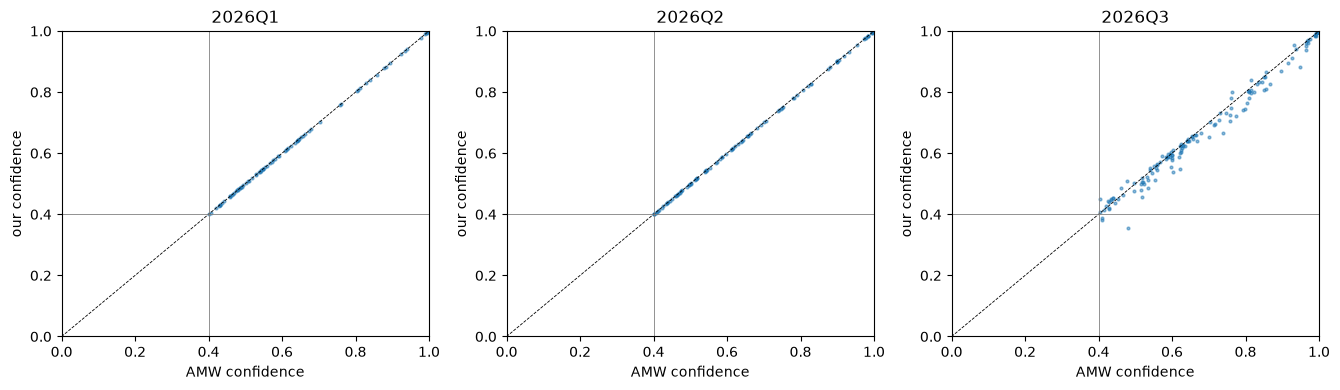

In [ ]:
display(pd.DataFrame(gaps).T)
fig, axes = plt.subplots(1, len(QUARTERS), figsize=(4.5 * len(QUARTERS), 4), squeeze=False)
for ax, q in zip(axes[0], QUARTERS):
    d = kept[q]
    ax.scatter(d["amw_confidence"], d["confidence"], s=4, alpha=0.5)
    ax.plot([0, 1], [0, 1], "k--", lw=0.6)
    ax.axhline(0.4, color="grey", lw=0.6); ax.axvline(0.4, color="grey", lw=0.6)
    ax.set(title=q, xlabel="AMW confidence", ylabel="our confidence", xlim=(0, 1), ylim=(0, 1))
plt.tight_layout()

## 5. Where and why they differ

| reason | what it looks like | check |
|---|---|---|
| **the last day**: our quarter includes it (31 Mar, 30 Jun, 30 Sep), AMW's doesn't maybe?(handoff §4) | gaps on all chips under that day's clear scenes, none elsewhere | 5e, and `scene_dates.py` |
| **Earth Engine's imagery changed** since AMW ran (scenes ingested late, or reprocessed) | the same, for any date | `scene_dates.py` lists ingestion dates |
| **border tiles**: AMW scored them twice (two subregion runs) and kept the higher score | gaps on border tiles only, ours lower | 5c |
| **scores right at 0.4** | disagreements sit near 0.4 | 5a |

### 5a. Near the threshold, and image quality (medians by outcome)

In [ ]:
for q in QUARTERS:
    d = kept[q][kept[q]["outcome"].isin(["only ours", "only AMW"])]
    near = ((d["confidence"] - 0.4).abs() <= 0.05).sum()
    print(f"{q}: {len(d)} disagreements, {near} of them with our score within 0.35-0.45")
pd.concat(quality, names=["quarter"])

2026Q1: 0 disagreements, 0 of them with our score within 0.35-0.45
2026Q2: 0 disagreements, 0 of them with our score within 0.35-0.45
2026Q3: 4 disagreements, 4 of them with our score within 0.35-0.45


confidence    n_obs  n_clear  empty_share
quarter outcome                                             
2026Q1  both          0.57918 20.00000 12.60872      0.00000
        neither       0.00000 20.00000 10.89453      0.00000
2026Q2  both          0.62211 26.00000  9.03602      0.00000
        neither       0.00002 26.00000  7.30773      0.00000
2026Q3  both          0.64660 27.00000 17.15234      0.00000
        neither       0.00001 27.00000 14.05642      0.00000
        only AMW      0.38140 27.00000 19.73828      0.00000
        only ours     0.40950 43.87500 26.82162      0.00000

### 5b. The six votes

If all six members differ by similar amounts, the images differ. If only one does, look at the
model or the vote order instead.

In [ ]:
vote_gaps = {}
for q in QUARTERS:
    both = kept[q][kept[q]["outcome"] == "both"]
    if "amw_preds" not in both or both.empty:
        continue
    ours = both[["chip_id"]].merge(compare.read_ours(RUN, q, SUBREGION, votes=True, only=both["chip_id"]),
                                   on="chip_id")
    mine = ours[[f"vote_{i}" for i in range(1, 7)]].to_numpy()
    vote_gaps[q] = np.median(np.abs(mine - compare.parse_votes(both["amw_preds"])), axis=0)
pd.DataFrame(vote_gaps, index=[f"vote_{i}" for i in range(1, 7)]).T.rename_axis("median |gap|")

,vote_1,vote_2,vote_3,vote_4,vote_5,vote_6
median |gap|,,,,,,
2026Q1,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000
2026Q2,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000
2026Q3,0.00131,0.00314,0.00110,0.00760,0.00166,0.01356


### 5c. Border tiles

In [ ]:
border = compare.border_tiles(RUN, SUBREGION)
print(f"{len(border):,} of our tiles were also scored by a neighbouring subregion's run")
if border:
    rows = {}
    for q in QUARTERS:
        d = kept[q].assign(border=kept[q]["tile"].isin(border),
                           gap=(kept[q]["confidence"] - kept[q]["amw_confidence"]).abs())
        rows[q] = d.groupby("border").agg(detected=("outcome", "size"),
                                          disagreements=("outcome", lambda o: o.isin(["only ours", "only AMW"]).sum()),
                                          median_gap=("gap", "median"))
    display(pd.concat(rows, names=["quarter"]))

0 of our tiles were also scored by a neighbouring subregion's run


### 5d. Whole tiles or scattered chips?

A tile whose detected chips are all identical saw the same images as AMW's. If the differing
tiles cluster in one part of the map (5e), they share a scene that only one side used.

In [ ]:
rows = {}
for q in QUARTERS:
    d = kept[q][kept[q]["outcome"] == "both"]
    gap = (d["confidence"] - d["amw_confidence"]).abs().groupby(d["tile"]).max()
    rows[q] = {"tiles with detections": len(gap), "all identical": int((gap <= 1e-6).sum()),
               "some differ": int((gap > 1e-6).sum())}
pd.DataFrame(rows).T

,tiles with detections,all identical,some differ
2026Q1,14,14,0
2026Q2,15,15,0
2026Q3,15,0,15


### 5e. Map

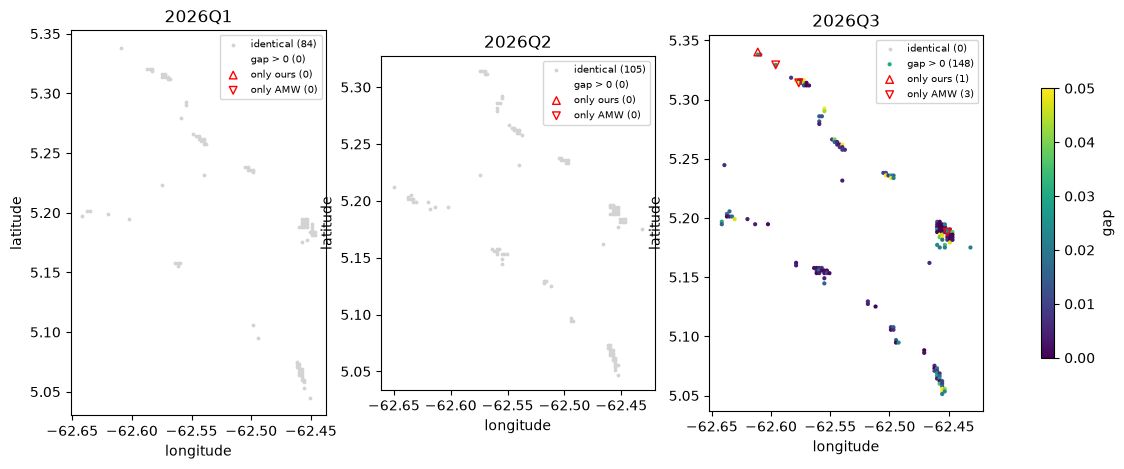

In [ ]:
footprints = {}
if CHECK_LAST_DAY:
    import scene_dates
    scene_dates.login(RUN)
    region = scene_dates.area(RUN)
    footprints = {q: scene_dates.last_day_footprint(region, q) for q in QUARTERS}

fig, axes = plt.subplots(1, len(QUARTERS), figsize=(5 * len(QUARTERS), 5), squeeze=False)
for ax, q in zip(axes[0], QUARTERS):
    d = kept[q].assign(gap=(kept[q]["confidence"] - kept[q]["amw_confidence"]).abs())
    same = d[d["gap"] <= 1e-6]
    differ = d[d["gap"] > 1e-6]
    ax.scatter(same["amw_key_x"], same["amw_key_y"], s=3, c="lightgrey", label=f"identical ({len(same)})")
    sc = ax.scatter(differ["amw_key_x"], differ["amw_key_y"], s=4, c=differ["gap"], cmap="viridis",
                    vmin=0, vmax=0.05, label=f"gap > 0 ({len(differ)})")
    for label, marker in (("only ours", "^"), ("only AMW", "v")):
        o = d[d["outcome"] == label]
        ax.scatter(o["amw_key_x"], o["amw_key_y"], s=30, marker=marker, facecolors="none",
                   edgecolors="red", label=f"{label} ({len(o)})")
    if q in footprints and not footprints[q].is_empty:
        for poly in getattr(footprints[q], "geoms", [footprints[q]]):
            ax.plot(*poly.exterior.xy, color="orange", lw=1)
        ax.plot([], [], color="orange", label="scenes of the last day")
    ax.set(title=q, xlabel="longitude", ylabel="latitude")
    ax.set_aspect("equal")
    ax.legend(fontsize=7, loc="best")
fig.colorbar(sc, ax=axes[0].tolist(), label="gap", shrink=0.7)

In [ ]:
if footprints:
    import shapely
    for q in QUARTERS:
        d = kept[q][kept[q]["outcome"] == "both"]
        under = shapely.contains_xy(footprints[q], d["amw_key_x"], d["amw_key_y"])
        gap = (d["confidence"] - d["amw_confidence"]).abs()
        print(f"{q}: identical under the last day's scenes {(gap[under] <= 1e-6).mean():.0%} "
              f"({under.sum()} chips), elsewhere {(gap[~under] <= 1e-6).mean():.0%} ({(~under).sum()} chips)")

## 6. Summary

In [ ]:
for q in QUARTERS:
    c, g = counts[q], gaps[q]
    print(f"{q}: ours {c['ours total']:,.0f}, AMW {c['AMW total']:,.0f} detections; "
          f"both {c['both']:,.0f}, only ours {c['only ours']:,.0f}, only AMW {c['only AMW']:,.0f} "
          f"(overlap {c['overlap (Jaccard)']:.3f}); scores identical for {g['identical (gap <= 1e-6)']:.0%}, "
          f"largest gap {g['largest gap']:.3f}")

2026Q1: ours 84, AMW 84 detections; both 84, only ours 0, only AMW 0 (overlap 1.000); scores identical for 100%, largest gap 0.000
2026Q2: ours 105, AMW 105 detections; both 105, only ours 0, only AMW 0 (overlap 1.000); scores identical for 100%, largest gap 0.000
2026Q3: ours 146, AMW 148 detections; both 145, only ours 1, only AMW 3 (overlap 0.973); scores identical for 0%, largest gap 0.074
